<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/14_CNN_P3_Padding_and_Stride.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Padding and Stride

So far, we have seen that the output of a convolution is usually **smaller** than its input.

For an input image of size **H × W** and a kernel of size **Kh × Kw**, the output size is:

```
(H − Kh + 1) × (W − Kw + 1)
```

This happens because the kernel can only be placed where it completely overlaps the input image.

As multiple convolutional layers are stacked, the feature maps continue to shrink. This may cause important information near the image boundaries to be lost.

Two techniques are commonly used to control the output size:

- **Padding** – adds extra pixels around the border of the image to preserve spatial information.
- **Stride** – controls how many pixels the kernel moves at each step, allowing the output to be reduced more quickly.

In this section, we will learn how **padding** and **stride** control the size of the output feature map.

In [ ]:
import tensorflow as tf


## Padding



Padding allows CNNs to preserve more spatial information and gives greater control over the output size.

TensorFlow provides two common padding options:

- **`padding="valid"`** – No padding is added. The output becomes smaller.
- **`padding="same"`** – Padding is automatically added so the output has approximately the same height and width as the input.

## Padding


For an input of size **H × W** and a kernel of size **Kh × Kw**, the output dimensions are:

$$
(H - K_h + 1)\times(W - K_w + 1)
$$

For example, applying a **3 × 3** kernel to a **10 × 10** image produces an output of

$$
(10 - 3 + 1)\times(10 - 3 + 1)=8\times8.
$$

As more convolutional layers are stacked together, the feature maps continue to shrink. Over many layers, information near the image boundaries is gradually lost because the outer pixels contribute to fewer convolution operations than the center pixels.

Padding solves this problem by adding extra pixels (typically zeros) around the border of the input image before applying the convolution.

If a total of **Ph** rows and **Pw** columns of padding are added, the output dimensions become

$$
(H - K_h + P_h + 1)\times(W - K_w + P_w + 1)
$$

A common choice is

```python
padding="same"
```

which automatically adds the required padding so that, when the stride is 1, the output has the **same height and width** as the input.

In the following examples, we verify that TensorFlow preserves the input dimensions when using `padding="same"` with different kernel sizes.



The figure below illustrates how zero-padding works.

A border of zeros is added around the original **3 × 3** image before applying the **2 × 2** kernel. Because the kernel now has additional positions where it can be placed, the output feature map becomes larger.

Notice that the convolution is performed exactly as before—the only difference is that the kernel is now allowed to overlap the padded zeros around the image boundary.

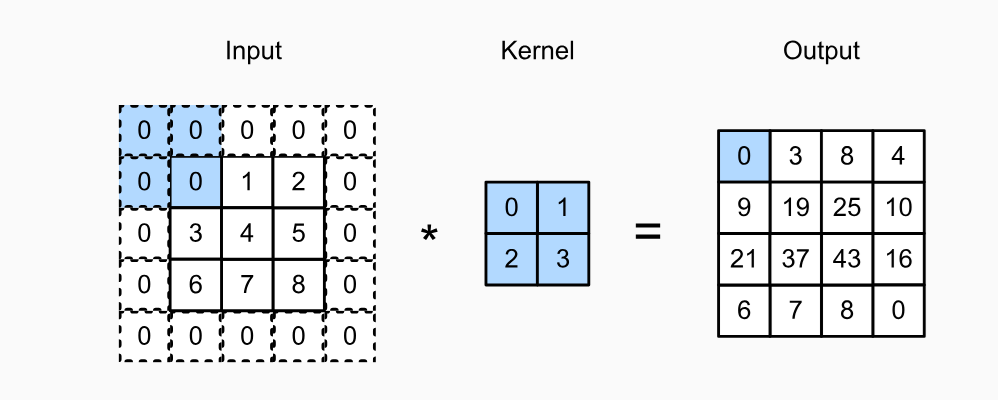

**Example 1**

The following example creates a convolutional layer with a **3 × 3 kernel** and `padding="same"`.

The input image has dimensions **8 × 8**. After the convolution, we verify that the output is also **8 × 8**, demonstrating that padding preserves the spatial dimensions.

In [ ]:
import tensorflow as tf

# -----------------------------------------------------------
# Helper function:
# Applies a Conv2D layer to a 2D image and returns only
# the spatial dimensions (height × width) of the output.
# -----------------------------------------------------------
def apply_conv2d(conv2d, X):

    # Conv2D expects input with shape:
    # (batch_size, height, width, channels)
    # Our image is only (height, width), so we add
    # one batch dimension and one channel dimension.
    X = tf.reshape(X, (1,) + X.shape + (1,))

    # Apply the convolution
    Y = conv2d(X)

    # Remove the batch and channel dimensions so
    # only the 2D feature map remains.
    return tf.reshape(Y, Y.shape[1:3])


# Create a random 8 × 8 grayscale image
X = tf.random.uniform(shape=(8, 8))

# Create a convolutional layer
# - One filter
# - 3 × 3 kernel
# - SAME padding preserves the spatial dimensions
conv2d = tf.keras.layers.Conv2D(
    filters=1,
    kernel_size=3,
    padding="same"
)

# Display the output shape
# Expected result: (8, 8)
apply_conv2d(conv2d, X).shape

TensorShape([8, 8])

**Example 2**

Padding also works when the kernel is **not square**.

In this example, we use a **5 × 3 kernel**. TensorFlow automatically computes the required padding in both directions so that the output still has the same height and width as the input.

This shows that `padding="same"` automatically handles different kernel shapes while preserving the input dimensions.

In [ ]:
# 5 × 3 kernel with SAME padding
conv2d = tf.keras.layers.Conv2D(
    filters=1,
    kernel_size=(5, 3),
    padding="same"
)

apply_conv2d(conv2d, X).shape

TensorShape([8, 8])

**Another Example:**
Suppose the input image is 6 × 6, and we use a 5 × 3 kernel with padding="same" and stride = 1.

TensorFlow adds:
- 2 rows at the top and 2 at the bottom.
- 1 column on the left and 1 on the right.
The padded input becomes 10 × 8, but after applying the convolution, the output is 6 × 6, the same as the original input.

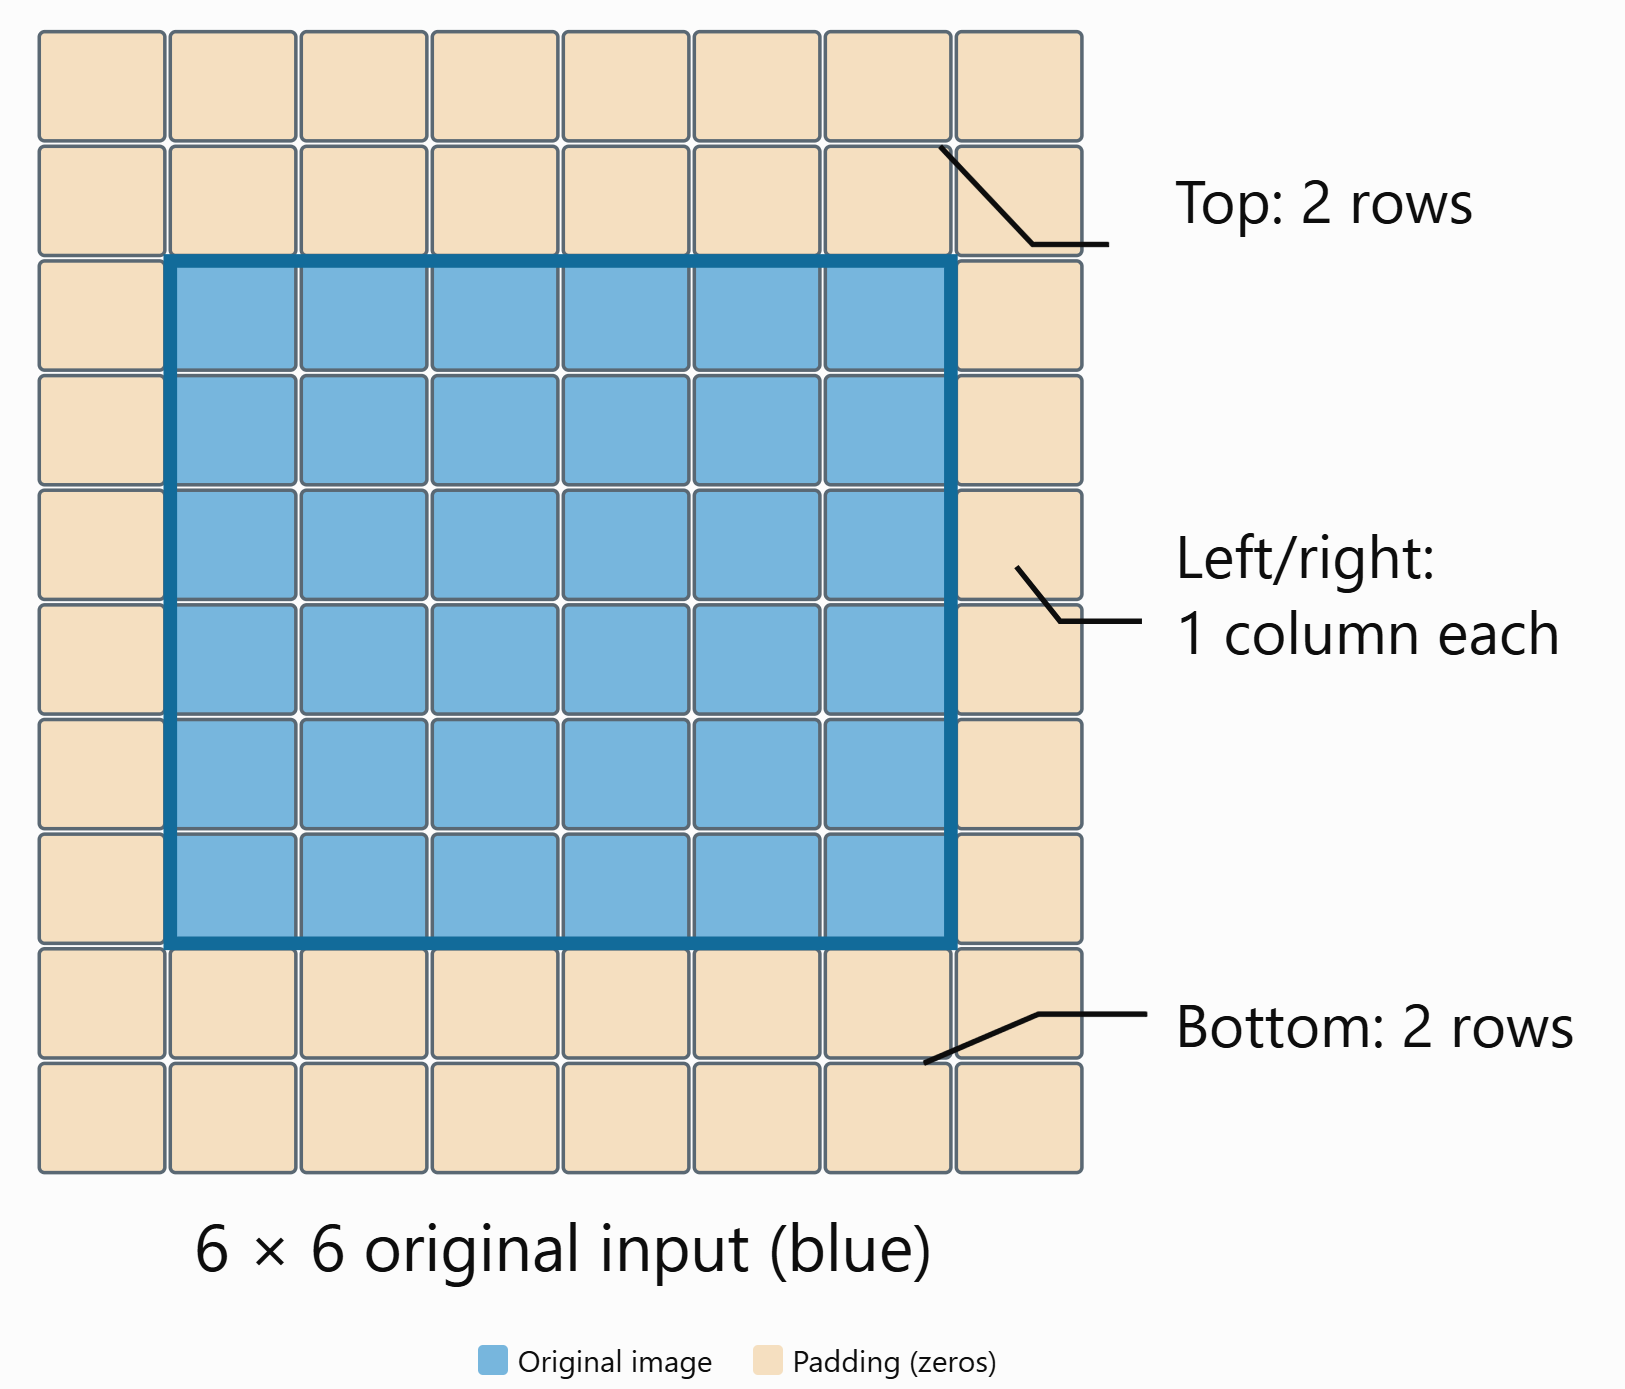

### Key Points

- Padding adds extra pixels around the image border.
- Zero padding is the most commonly used type of padding.
- Padding helps preserve information near the image boundaries.
- `padding="valid"` applies no padding.
- `padding="same"` automatically pads the input to preserve the spatial dimensions.

## Stride

So far, we have moved the convolution kernel **one pixel at a time** across the image. This corresponds to a **stride of 1**, which is the default in most convolutional layers.

Sometimes, however, we want the kernel to move by **more than one pixel** at each step. The number of pixels the kernel moves between consecutive positions is called the **stride**.

Increasing the stride has two important effects:

- The kernel visits fewer locations.
- The output feature map becomes smaller.

This allows the network to reduce the spatial dimensions of the data while also decreasing the computational cost.

For example,

- **Stride = 1:** the kernel moves one pixel at a time.
- **Stride = 2:** the kernel skips one pixel between positions.
- **Stride = 3:** the kernel moves three pixels each time.

As the stride increases, fewer output values are produced because the kernel is evaluated at fewer locations.

### Example

Suppose we have an **8 × 8** input image and apply a **3 × 3** convolution.

| Stride | Output Size |
|---------|-------------|
| 1 | 6 × 6 (without padding) |
| 2 | 3 × 3 |
| 3 | 2 × 2 |

Larger strides are commonly used when we want to **downsample** the feature maps instead of processing every pixel location.

### Demonstration: Stride = 2

The following example creates a convolutional layer using:

- one filter,
- a 3 × 3 kernel,
- SAME padding,
- stride = 2.

Because the kernel moves two pixels at a time, the output dimensions are reduced from **8 × 8** to **4 × 4**.

In [ ]:
# Convolution with a 3 × 3 kernel
# SAME padding preserves borders
# Stride = 2 downsamples the feature map

conv2d = tf.keras.layers.Conv2D(
    filters=1,
    kernel_size=3,
    padding="same",
    strides=2
)

apply_conv2d(conv2d, X).shape

TensorShape([4, 4])

In [ ]:
# Convolution with a 3 × 3 kernel
# SAME padding preserves borders
# Stride = 2 downsamples the feature map

conv2d = tf.keras.layers.Conv2D(
    filters=1,
    kernel_size=3,
    padding="valid",
    strides=2
)

apply_conv2d(conv2d, X).shape

TensorShape([3, 3])

### Demonstration: Different Strides Along Each Dimension

Stride values can be specified independently for the height and width.

In this example,

- kernel size = **3 × 5**
- padding = **VALID**
- vertical stride = **3**
- horizontal stride = **4**

The kernel moves three pixels vertically and four pixels horizontally, producing an even smaller output feature map.

In [ ]:
# Different strides for height and width

conv2d = tf.keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 5),
    padding="valid",
    strides=(3, 4)
)

apply_conv2d(conv2d, X).shape

TensorShape([2, 1])

> **Rule of thumb:** Increasing the stride causes the kernel to skip positions, producing a smaller output feature map.
>
> Frameworks such as TensorFlow and PyTorch automatically compute the output size based on the input size, kernel size, padding, and stride.

### Output Size

Without padding (`padding="valid"`):

Output Size = floor((Input Size − Kernel Size) / Stride) + 1

With SAME padding (`padding="same"`):

Output Size = ceil(Input Size / Stride)

Example 1

Input = 8
Kernel = 3
Stride = 1

Output = floor((8 - 3) / 1) + 1
       = floor(5) + 1
       = 6

Example 2

Input = 8
Kernel = 3
Stride = 2

Output = floor((8 - 3) / 2) + 1
       = floor(2.5) + 1
       = 3

Example 3 (SAME Padding)

Input = 8
Stride = 2

Output = ceil(8 / 2)
       = 4

## Summary

In this section, we introduced two important techniques that control the size of the output feature maps produced by convolutional layers.

### Padding

- Padding adds extra pixels (usually zeros) around the image boundary.
- It helps preserve spatial dimensions after convolution.
- It prevents excessive shrinking of feature maps when many convolutional layers are stacked.
- The most common choice is **zero padding** with `padding="same"`.

### Stride

- Stride determines how many pixels the kernel moves at each step.
- A larger stride reduces the size of the output feature map.
- Larger strides also reduce the amount of computation by evaluating fewer kernel positions.

### Key Takeaways

- **Padding** preserves spatial information by adding pixels around the image.
- **Stride** controls the amount of downsampling.
- By default, most convolutional layers use:
  - `padding = "valid"` (no padding), or `padding = "same"` (preserve dimensions)
  - `stride = 1`
- Padding and stride are fundamental hyperparameters that determine the spatial dimensions of feature maps throughout a CNN.